# NLP: tokenisation, normalisation and bag of words — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D011_C2_Bag_of_Words.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# C2: Bag of Words and TF-IDF

In the previous notebook, we learned how to clean and preprocess text. Now, we need to convert that text into a format that machine learning models can understand: **Numbers**.

This process is called **Feature Extraction** or **Vectorization**.

## 1. The Bag of Words (BoW) Model

The **Bag of Words** model is one of the simplest ways to represent text data. 

**Core Concept**: 
1.  We ignore grammar and word order.
2.  We just count how many times each word appears.
3.  The text is imagined as a "bag" of words mixed together.

### Visual Concept

Imagine two sentences:
*   **Sentence A**: "The cat sat on the mat"
*   **Sentence B**: "The dog sat on the log"

Our **vocabulary** (unique words) is: `['cat', 'dog', 'log', 'mat', 'on', 'sat', 'the']`

Each sentence becomes a vector of counts based on this dictionary:

| Vocabulary | cat | dog | log | mat | on | sat | the |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Sentence A** | 1 | 0 | 0 | 1 | 1 | 1 | 2 |
| **Sentence B** | 0 | 1 | 1 | 0 | 1 | 1 | 2 |

This matrix is what we feed into our models.

### Diagram: From Text to BoW

![Bag of Words](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fdatascientyst.com%2Fcontent%2Fimages%2F2023%2F01%2Fbag_of_words_python.webp&f=1&nofb=1&ipt=6772f1da120a21905af33b177a08ad4eed2e6de87bfa8bd97e2ffd4992e5a4b6)

## 2. Implementing BoW in Python

We use `CountVectorizer` from the `scikit-learn` library.

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Sample Corpus
corpus = [
    "I love natural language processing.",
    "Language processing is fun.",
    "I love python."
]

# 2. Instantiate the Vectorizer
vectorizer = CountVectorizer(stop_words='english')

# 3. Fit and Transform
# This learns the vocabulary AND converts the text to numbers at the same time
bow_matrix = vectorizer.fit_transform(corpus)

# 4. View the result
# We convert to a DataFrame for readability (Terms are columns, Documents are rows)
df_bow = pd.DataFrame(bow_matrix.toarray(), columns=vectorizer.get_feature_names_out())
df_bow.index = [f"Doc {i+1}" for i in range(len(corpus))]

print("Vocabulary:", vectorizer.get_feature_names_out())
print("\nBoW Matrix:")
display(df_bow)

Vocabulary: ['fun' 'language' 'love' 'natural' 'processing' 'python']

BoW Matrix:


,fun,language,love,natural,processing,python
Doc 1,0,1,1,1,1,0
Doc 2,1,1,0,0,1,0
Doc 3,0,0,1,0,0,1


In [ ]:
# ═══ CHECKPOINT — "Sparsity" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
corpus = ['I love natural language processing.', 'Language processing is fun.', 'I love python.']
vectorizer = CountVectorizer(stop_words='english')
bow_matrix = vectorizer.fit_transform(corpus)
df_bow = pd.DataFrame(bow_matrix.toarray(), columns=vectorizer.get_feature_names_out())
df_bow.index = [f'Doc {i + 1}' for i in range(len(corpus))]

print("Checkpoint restored. Ready for: Sparsity")

### Sparsity

In real-world datasets with thousands of words, most documents will NOT contain most words. This means the matrix will be mostly zeros. This is called a **Sparse Matrix**.

Scikit-learn stores these efficiently (only remembering the non-zero values) to save memory.

## 3. The Problem with Raw Counts

Counting words is a good start, but it has a flaw:
*   Common words (like "good", "movie", "book") might appear frequently in ALL documents.
*   Just because they are frequent doesn't mean they are *important* or *unique* to that specific document.

**Solution**: We need to penalize words that are too common across the entire dataset. Enter **TF-IDF**.

## 4. TF-IDF (Term Frequency - Inverse Document Frequency)

TF-IDF gives us a score that tells us: **"How relevant is this word to this specific document?"**

It has two parts:

1.  **TF (Term Frequency)**: How many times does word $w$ appear in document $d$? (Same as BoW).
    *   *Logic*: More frequent = more important.

2.  **IDF (Inverse Document Frequency)**: How rare is word $w$ across ALL documents?
    *   *Logic*: Rare words are more significant (informative) than common ones.

### The Formula

$$ \text{TF-IDF} = \text{TF} \times \log\left(\frac{N}{DF}\right) $$

*   **TF**: Count of word in doc.
*   **N**: Total number of documents.
*   **DF**: Number of documents containing the word.

If a word appears in EVERY document ($N = DF$), then $\log(1) = 0$, so the TF-IDF score becomes 0 (it's ignored!).

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Using the same corpus
tfidf_vectorizer = TfidfVectorizer(stop_words='english')

# Fit and Transform
tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)

# View result
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out())
df_tfidf.index = [f"Doc {i+1}" for i in range(len(corpus))]

print("TF-IDF Matrix:")
display(df_tfidf)

TF-IDF Matrix:


,fun,language,love,natural,processing,python
Doc 1,0.000000,0.459854,0.459854,0.604652,0.459854,0.000000
Doc 2,0.680919,0.517856,0.000000,0.000000,0.517856,0.000000
Doc 3,0.000000,0.000000,0.605349,0.000000,0.000000,0.795961


Notice how the scores are decimals now. Unique words like "fun" or "python" get higher scores than repeated terms.

## 5. Cosine Similarity

Once we have these vectors (BoW or TF-IDF), we can measure how similar two documents are.

Distance (Euclidean) is often a bad metric for text because long documents will naturally be "farther" from short documents even if they talk about the same topic. 

Instead, we use the **Angle** between the vectors.

*   **Small Angle** = High Similarity (Vectors point in same direction)
*   **Large Angle (90°)** = No Similarity (Vectors are unrelated)

### Dynamic Diagram: Vectors and Angles
We will generate this diagram using Python to show exactly what's happening.

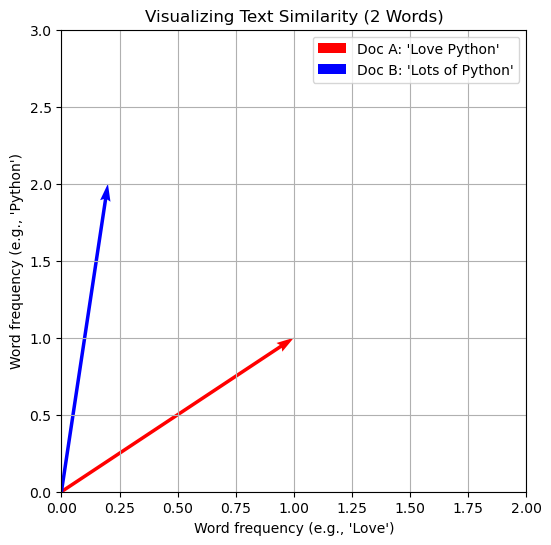

In [3]:
import matplotlib.pyplot as plt
import numpy as np

def plot_vectors(v1, v2, labels):
    plt.figure(figsize=(6, 6))
    plt.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='r', label=labels[0])
    plt.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='b', label=labels[1])

    plt.xlim(0, max(v1[0], v2[0]) + 1)
    plt.ylim(0, max(v1[1], v2[1]) + 1)
    plt.grid(True)
    plt.legend()
    plt.title(f"Visualizing Text Similarity (2 Words)")
    plt.xlabel("Word frequency (e.g., 'Love')")
    plt.ylabel("Word frequency (e.g., 'Python')")
    plt.show()

# Imagine a simplified world with only 2 words: "Love" and "Python"
# Doc A: "Love Python" -> Vector [1, 1]
# Doc B: "Python Python" -> Vector [0, 2]

v_a = [1, 1]
v_b = [0.2, 2]

plot_vectors(v_a, v_b, labels=["Doc A: 'Love Python'", "Doc B: 'Lots of Python'"])

### Calculating Similarity

In [4]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between the first document and all others in our corpus
similarity = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix)

print(f"Reference Doc: '{corpus[0]}'")
print("Similiarities:")
for i, score in enumerate(similarity[0]):
    print(f" - Doc {i+1} ('{corpus[i]}'): {score:.4f}")

Reference Doc: 'I love natural language processing.'
Similiarities:
 - Doc 1 ('I love natural language processing.'): 1.0000
 - Doc 2 ('Language processing is fun.'): 0.4763
 - Doc 3 ('I love python.'): 0.2784


## 6. Practical Exercise: Product Reviews

Let's find similar reviews in our dataset.

In [ ]:
# TODO: compute `df`, `tfidf`, `tfidf_matrix` from `Text`
# Hint: pd.read_csv, .fillna(), TfidfVectorizer, tfidf.fit_transform
# Name your result: df, tfidf, tfidf_matrix

In [ ]:
# ═══ CHECKPOINT — "Search Engine" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
corpus = ['I love natural language processing.', 'Language processing is fun.', 'I love python.']
vectorizer = CountVectorizer(stop_words='english')
bow_matrix = vectorizer.fit_transform(corpus)
df_bow = pd.DataFrame(bow_matrix.toarray(), columns=vectorizer.get_feature_names_out())
df_bow.index = [f'Doc {i + 1}' for i in range(len(corpus))]
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out())
df_tfidf.index = [f'Doc {i + 1}' for i in range(len(corpus))]
import matplotlib.pyplot as plt
import numpy as np
def plot_vectors(v1, v2, labels):
    plt.figure(figsize=(6, 6))
    plt.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='r', label=labels[0])
    plt.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='b', label=labels[1])
    plt.xlim(0, max(v1[0], v2[0]) + 1)
    plt.ylim(0, max(v1[1], v2[1]) + 1)
    plt.grid(True)
    plt.legend()
    plt.title(f'Visualizing Text Similarity (2 Words)')
    plt.xlabel("Word frequency (e.g., 'Love')")
    plt.ylabel("Word frequency (e.g., 'Python')")
    plt.show()
v_a = [1, 1]
v_b = [0.2, 2]
from sklearn.metrics.pairwise import cosine_similarity
similarity = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix)
df = pd.read_csv('../../00-data/NLP Product Reviews.csv')
df['Text'] = df['Text'].fillna('')
tfidf = TfidfVectorizer(stop_words='english', max_features=100)
tfidf_matrix = tfidf.fit_transform(df['Text'])

print("Checkpoint restored. Ready for: Search Engine")

### Search Engine
We can build a basic search engine! We convert a query into a vector and find the closest matching review vector.

In [ ]:
# TODO: compute `query`, `query_vec`, `scores` from `Text`
# Hint: tfidf.transform, .flatten(), cosine_similarity, scores.argsort
# Name your result: query, query_vec, scores, top_indices

## 7. Exercises

### Exercise 1: BoW for Movies
Given the list `movies`, create a BoW matrix (without stop words) and print the vocabulary.

`movies = ["Star Wars is a great sci-fi movie", "The Notebook is a romantic movie"]`

In [7]:
# Your Code Here


### Exercise 2: Identify Similarity
Which of the two movies in Exercise 1 is more similar to the query below?

`query_movie = "I love science fiction movies"`

Use `CountVectorizer` or `TfidfVectorizer` and `cosine_similarity`.

In [8]:
# Your Code Here
